### **Student Information**
GitHub ID:

Kaggle name:

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

**Syntax:** `#` creates the largest heading (H1).

---
**Syntax:** `---` creates a horizontal rule (a separator line).

## 1. Model Development (10 pts Required)

**Syntax:** `##` creates a secondary heading (H2).

**Describe briefly each section, you can add graphs/charts to support your explanations.**

### 1.1 Preprocessing Steps

**Syntax:** `###` creates a tertiary heading (H3).

[Content for Preprocessing]

**Example Syntax for Content:**
*   **Bold text:** `**text**`
*   *Italic text*: `*text*`
*   Bullet point list:
    * Item 1
    * Item 2

Markdown Syntax to Add Image: `![Description of the Image](./your_local_folder/name_of_the_image.png)`

![Example Markdown Syntax to Add Image](./pics/example_md_img.png)

### 1.2 Feature Engineering Steps

[Content for Feature Engineering]

### 1.3 Explanation of Your Model

[Content for Model Explanation]

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

[Content for AI Prompts and your reason]

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

### 1.1 Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import html

# NLTK
import re
import collections
import nltk
nltk.download("stopwords")
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split

LABELS = ["joy", "anger", "sadness", "disgust", "surprise", "fear"]
SEED = 42

[nltk_data] Downloading package stopwords to /home/enarde/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### 1.2 Data Loading

In [2]:
### Add the code related to the preprocessing steps in cells inside this section
DATA_DIR = "data/kaggle"

# Load the raw files
posts = pd.read_json(f"{DATA_DIR}/final_posts.json")
split = pd.read_csv(f"{DATA_DIR}/data_identification.csv")
labels = pd.read_csv(f"{DATA_DIR}/emotion.csv")

# Join on post_id
df = posts.merge(split, on="post_id").merge(labels, on="post_id", how="left")

train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df = df[df["set"] == "test"].reset_index(drop=True)

print(train_df.shape, test_df.shape) # (3360, 4) (1440, 4)
print(train_df["label"].value_counts())
train_df.head()

(3360, 4) (1440, 4)
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


,post_id,text,set,label
0,f8bv5zh,Thought it looked weird as well.,train,disgust
1,q0rr1l9,Bear died in a pit,train,disgust
2,p94rwgk,I have endured worse.,train,sadness
3,9u6wtvm,The pottery around Brasov is in danger,train,fear
4,h8ea329,"Meanwhile, our soldiers were approaching the a...",train,fear


In [3]:
# Missing labels for test data is expected
for name, d in {"train": train_df, "test": test_df}.items():
    print(f"--- {name} ---")
    print("shape:", d.shape)
    print("missing values per column:")
    print(d.isna().sum())
    print()

--- train ---
shape: (3360, 4)
missing values per column:
post_id    0
text       0
set        0
label      0
dtype: int64

--- test ---
shape: (1440, 4)
missing values per column:
post_id       0
text          0
set           0
label      1440
dtype: int64



In [4]:
for name, d in {"train": train_df, "test": test_df}.items():
    print(f"--- {name} ---")
    print("Column data types:")
    print(d.dtypes)
    print()
    print("Duplicate ids:")
    print(d["post_id"].duplicated().sum())
    print("Duplicate texts:")
    print(d["text"].duplicated().sum())
    print("Duplicate texts with same label:")
    print(d.duplicated(subset=["text", "label"]).sum())
    print()
    print("Unique emotion labels:")
    for emotion in d['label'].unique():
        print(emotion)
    print()

print("Number of texts appearing in both train and test:")
shared = set(train_df["text"]) & set(test_df["text"])
print(len(shared))

--- train ---
Column data types:
post_id    str
text       str
set        str
label      str
dtype: object

Duplicate ids:
0
Duplicate texts:
50
Duplicate texts with same label:
34

Unique emotion labels:
disgust
sadness
fear
joy
anger
surprise

--- test ---
Column data types:
post_id    str
text       str
set        str
label      str
dtype: object

Duplicate ids:
0
Duplicate texts:
8
Duplicate texts with same label:
8

Unique emotion labels:
nan

Number of texts appearing in both train and test:
59


In [5]:
# remove duplicates from training data
train_df = train_df.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
print("Duplicate texts with same label (Training):")
print(train_df.duplicated(subset=["text", "label"]).sum())

Duplicate texts with same label (Training):
0


### Exploration of contents

In [6]:
# Check the most common characters used in the texts
chars = collections.Counter(ch for s in train_df.text for ch in s
                            if not ch.isalnum() and not ch.isspace())
chars.most_common(40)

[('.', 3120),
 (',', 2773),
 ("'", 1530),
 ('!', 591),
 ('?', 346),
 (']', 274),
 ('[', 273),
 ('’', 259),
 ('>', 194),
 ('"', 186),
 ('-', 178),
 ('<', 176),
 (':', 175),
 ('@', 175),
 ('#', 133),
 ('*', 83),
 (')', 81),
 ('😂', 62),
 ('(', 53),
 ('/', 53),
 ('😭', 47),
 (';', 30),
 ('️', 29),
 ('”', 20),
 ('“', 19),
 ('%', 13),
 ('♪', 13),
 ('^', 12),
 ('🥰', 11),
 ('🙏', 11),
 ('❤', 10),
 ('😁', 10),
 ('🤣', 10),
 ('~', 8),
 ('👏', 7),
 ('🤔', 7),
 ('$', 6),
 ('+', 5),
 ('♂', 5),
 ('🙄', 4)]

In [7]:
# Identify commonly occurring templates and patterns in the text
def shape(w):
    w = re.sub(r"\d+", "9", w)
    w = re.sub(r"[A-Z]+", "A", w)
    return re.sub(r"[a-z]+", "a", w)

odd = [w for s in train_df.text for w in s.split() if re.search(r"[^\w'.,!?\"’]", w)]
collections.Counter(shape(w) for w in odd).most_common(30)

[('[A]', 201),
 ('@<a>', 172),
 ('Aa:', 67),
 ('a-a', 42),
 ('a:', 33),
 ('-', 32),
 ('[A].', 30),
 ('a;', 23),
 ('[A],', 20),
 ('a/a', 19),
 ('(a', 15),
 ('♪', 13),
 ('##A###', 11),
 ('a)', 11),
 (':)', 11),
 ('*a*', 10),
 (':(', 10),
 ('Aa-Aa', 10),
 ('#a', 10),
 ('>', 9),
 ('a*', 9),
 ('#Aa', 8),
 ('9%', 8),
 ('##A##', 7),
 ('a”', 7),
 ('“a', 6),
 ('a-a,', 6),
 ('a).', 6),
 ('*a', 6),
 ('*Aa', 6)]

In [8]:
# List bracketed or marked words in the texts
collections.Counter(re.findall(r"[\[<{#][\w#]+[\]>}#]*", " ".join(train_df.text))).most_common(20)

[('[NAME]', 270),
 ('<username>', 173),
 ('##URL###', 11),
 ('##URL##', 7),
 ('#RwOT', 3),
 ('<3', 2),
 ('#Famille', 1),
 ('##URL####', 1),
 ('#PLAY', 1),
 ('#CHOGM2022', 1),
 ('#Pizzets', 1),
 ('#Fact', 1),
 ('#1', 1),
 ('[Think]', 1),
 ('#HorrorBaro', 1),
 ('#VfB', 1),
 ('#likeapig', 1),
 ('#Alert', 1),
 ('#blessingswe', 1),
 ('#oromoliberationarmy', 1)]

### 1.3 Data Cleaning & Standardizing

In [9]:
def clean_text(text):
    # Decode HTML entities first (&amp; -> &), so later rules see real characters
    text = html.unescape(text)

    # Remove invisible emoji modifiers, so ❤️ and ❤ become the same token
    text = text.replace("\ufe0f", "").replace("\u200d", "")

    # Strip HTML tags like <li>, <i>, </b>. The (?!username>) part skips
    #    <username>, which is handled in the next rule
    text = re.sub(r"<(?!username>)/?[a-zA-Z]+\s*/?>", " ", text)

    # Placeholders -> consistent tokens
    text = re.sub(r"@<username>|@\w+", " USERTOKEN ", text)
    text = re.sub(r"#*\bURL\b#*|https?://\S+|www\.\S+", " URLTOKEN ", text) # all ##URL### variants
    text = re.sub(r"\[NAME\]", " NAMETOKEN ", text)
    text = re.sub(r"\[RELIGION\]", " RELIGIONTOKEN ", text)
    text = re.sub(r"\b[ru]/\w+", " REDDITTOKEN ", text)

    # Reddit formatting: keep the words, drop the markup
    text = re.sub(r"^\s*>+\s*", "", text)          # quote marker at the start of a post
    text = re.sub(r"~~(.+?)~~", r"\1", text)       # ~~strikethrough~~
    text = re.sub(r"\*+([^*]+?)\*+", r"\1", text)  # *action* and **bold**

    # Music notes mark lyrics or singing
    text = re.sub(r"♪+", " MUSICTOKEN ", text)

    # Hashtags: keep the word, drop the '#'. This runs after the URL rule
    #    so ##URL## isn't damaged
    text = re.sub(r"#(\w+)", r"\1", text)

    # Curly quotes -> straight quotes, then collapse whitespace
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", text).strip()

In [10]:
# TweetTokenizer keeps emoji and contractions, and shortens "sooooo" to "sooo"
tok = TweetTokenizer(preserve_case=False, reduce_len=True)

# Keep negations: removing "not" turns "not happy" into "happy"
NEGATIONS = {"no", "not", "nor", "never", "don't", "didn't", "isn't", "wasn't",
             "can't", "won't", "shouldn't", "couldn't", "doesn't", "aren't"}
STOP = set(stopwords.words("english")) - NEGATIONS

def tokenize(text, remove_stop=False):
    toks = tok.tokenize(text)
    if remove_stop:
        toks = [t for t in toks if t not in STOP]
    return toks

train_df["clean_text"] = train_df["text"].map(clean_text)
train_df["tokens"] = train_df["clean_text"].map(tokenize)
test_df["clean_text"] = test_df["text"].map(clean_text)
test_df["tokens"] = test_df["clean_text"].map(tokenize)

In [11]:
# Most common tokenizer outputs
collections.Counter(x for s in train_df.text for x in tokenize(clean_text(s))
                    if not re.fullmatch(r"[A-Za-z']+|[.,!?\"]+", x)).most_common(30)

[(':', 129),
 ('-', 69),
 (')', 64),
 ('😂', 54),
 ('(', 40),
 ('/', 39),
 ('😭', 37),
 (';', 29),
 (':)', 15),
 ('%', 13),
 ('^', 12),
 (':(', 11),
 ('*', 11),
 ('2', 10),
 ('19', 10),
 ('3', 10),
 ('8', 10),
 ('🥰', 10),
 ('❤', 10),
 ('🙏', 10),
 ('🤣', 10),
 ('30', 9),
 ('1', 9),
 ('😁', 9),
 ('100', 7),
 ('10', 7),
 ('👏', 7),
 ('20', 7),
 ('🤔', 7),
 ('4', 6)]

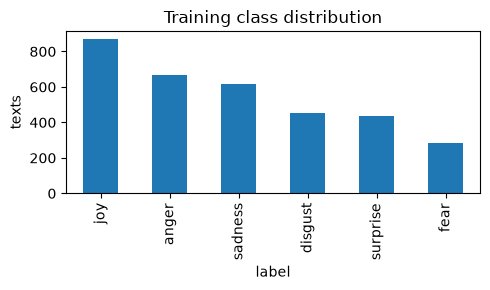

In [12]:
fig, ax = plt.subplots(figsize=(5, 3))
train_df["label"].value_counts().reindex(LABELS).plot(kind="bar", ax=ax, color="tab:blue")
ax.set_title("Training class distribution"); ax.set_ylabel("texts")
plt.tight_layout(); plt.show()

          count  mean   std  min   25%   50%   75%    max
label                                                    
anger     667.0  20.3  36.5  2.0   9.0  14.0  22.0  509.0
disgust   451.0  18.7  28.9  1.0   9.0  14.0  22.0  506.0
fear      282.0  17.1  17.5  3.0   9.0  15.0  21.0  242.0
joy       870.0  20.4  36.2  2.0   9.0  14.0  21.0  508.0
sadness   619.0  18.2  20.6  1.0  10.0  15.0  21.0  387.0
surprise  437.0  14.9   8.5  2.0   9.0  14.0  19.0   79.0


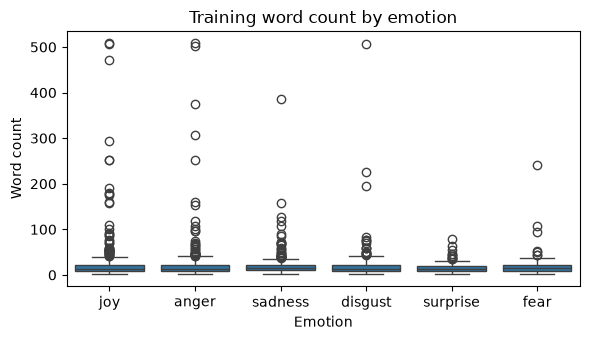

In [13]:
# Text length, counted in tokens, summarized per emotion.
train_df["word_count"] = train_df["tokens"].map(len)
print(train_df.groupby("label")["word_count"].describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))

sns.boxplot(data=train_df, x="label", y="word_count",order=LABELS, ax=ax)
ax.set_title("Training word count by emotion")
ax.set_xlabel("Emotion")
ax.set_ylabel("Word count")

plt.tight_layout()
plt.show()

In [14]:
# Unique-token ratio: share of tokens in a post that are distinct (low = repetition loop)
train_df["unique_ratio"] = train_df["tokens"].map(lambda t: len(set(t)) / len(t))
print("loop posts (<30% unique tokens):", (train_df["unique_ratio"] < 0.3).sum())

N_PER_LABEL = 3
PREVIEW_CHARS = 200

# Sort by length, keep the N longest per label, then order by label for display
longest = (train_df.sort_values("word_count", ascending=False)
                   .groupby("label", sort=False)
                   .head(N_PER_LABEL)
                   .sort_values(["label", "word_count"], ascending=[True, False]))

for label, group in longest.groupby("label"):
    print(f"\n=== {label.upper()} ===")
    for _, row in group.iterrows():
        flag = "LOOP" if row.unique_ratio < 0.3 else "    "
        print(f"[{flag}] {row.word_count:4d} tokens | unique {row.unique_ratio:.0%} | "
              f"{row.clean_text[:PREVIEW_CHARS]}...")

loop posts (<30% unique tokens): 27

=== ANGER ===
[LOOP]  509 tokens | unique 4% | I was really shy, in the first place, when I was in charge of the cargo, and I was really in charge of the cargo, and I was in the kitchen, and I was in the kitchen, and I was in the kitchen, and I wa...
[LOOP]  502 tokens | unique 6% | Today 2014 democracy scholars who are waiting for you see you waiting for you Habiba Siraj omn conscience is fighting and we are waiting for the truth in our lives we are afraid of life and we are for...
[LOOP]  375 tokens | unique 5% | The world is a terrible place to live if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it i...

=== DISGUST ===
[LOOP]  506 tokens | unique 4% | I'm wearing a suit and I'm learning Somali. Oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, 

In [15]:
def collapse_repeats(tokens, max_n=10, max_copies=2):
    """Collapse a phrase of 1..max_n tokens repeated back-to-back into at most max_copies."""
    out = list(tokens)
    for n in range(1, max_n + 1):
        i, res = 0, []
        while i < len(out):
            chunk = out[i:i + n]
            copies = 1
            while len(chunk) == n and out[i + copies * n:i + (copies + 1) * n] == chunk:
                copies += 1
            if copies > 1:
                res.extend(chunk * min(copies, max_copies))
                i += n * copies
            else:
                res.append(out[i])
                i += 1
        out = res
    return out

In [16]:
train_df["tokens"] = train_df["tokens"].map(collapse_repeats)
test_df["tokens"] = test_df["tokens"].map(collapse_repeats)

unique_ratio = lambda toks: len(set(toks)) / len(toks)
print("loop posts (<30% unique tokens):", (train_df["tokens"].map(unique_ratio) < 0.3).sum())
print("longest post (tokens):", train_df["tokens"].map(len).max())

loop posts (<30% unique tokens): 11
longest post (tokens): 153


In [17]:
# Unstratified: rows are shuffled and split at random
tr_df, val_df = train_test_split(train_df, test_size=0.2, random_state=SEED)
tr_y = tr_df["label"]
val_y = val_df["label"]

# Stratified: each label keeps the same proportion in both parts
str_tr_df, str_val_df = train_test_split(train_df, test_size=0.2, random_state=SEED,
                                 stratify=train_df["label"])

## 2. Feature Engineering Steps

In [18]:
### Add the code related to the feature engineering steps in cells inside this section
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import os
from sentence_transformers import SentenceTransformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
import torch
from scipy.special import softmax, expit
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification
from sklearn.pipeline import make_pipeline

In [19]:
EMBEDDERS = {
    "minilm": "sentence-transformers/all-MiniLM-L6-v2",
    "mpnet":  "sentence-transformers/all-mpnet-base-v2",
}

EMB_DIR = "data/kaggle/embeddings"
os.makedirs(EMB_DIR, exist_ok=True)

EMOTION_MODELS = {
    "jhartmann": "j-hartmann/emotion-english-distilroberta-base",  # 7 labels, single-label (softmax)
    "samlowe":   "SamLowe/roberta-base-go_emotions",               # 28 labels, multi-label (sigmoid)
}
EMOTION_KIND = {"jhartmann": "single", "samlowe": "multi"}
EMO_DIR = "data/kaggle/emotion_logits"
os.makedirs(EMO_DIR, exist_ok=True)
torch.set_num_threads(6)  # limit CPU threads, leaves room for the kernel

In [20]:
def identity(tokens):
    # Tokens are already lists from preprocessing, so pass them through unchanged
    return tokens

def make_tfidf(**kwargs):
    """TF-IDF over pre-tokenized posts. Uses the tokenizer slot (not analyzer),
    so ngram_range and the other word options still apply."""
    return TfidfVectorizer(tokenizer=identity, preprocessor=identity,
                           lowercase=False, token_pattern=None, **kwargs)

def build_features(train_part, val_part):
    """Fit TF-IDF on the training part only, then transform both parts."""
    vec = make_tfidf()
    X_train = vec.fit_transform(train_part["tokens"])
    X_val = vec.transform(val_part["tokens"])
    return vec, X_train, X_val

def encode_cached(model_name, texts, cache_file):
    """Encode texts with a pretrained sentence embedder, or load a previous run from disk."""
    if os.path.exists(cache_file):
        return np.load(cache_file)
    model = SentenceTransformer(model_name, device="cpu")
    # normalize_embeddings=True gives each vector length 1, the same scale as a TF-IDF row
    emb = model.encode(list(texts), batch_size=32,
                       normalize_embeddings=True, show_progress_bar=True)
    np.save(cache_file, emb)
    return emb

def stack_embeddings(col):
    # A column holding one array per row -> a 2-D matrix (n_posts x dims)
    return np.vstack(col.values)

def make_emb_features(emb_col, emb_weight=1.0, **tfidf_kwargs):
    """TF-IDF (same make_tfidf as the TF-IDF-only model) side by side with one embedding column."""
    return ColumnTransformer(
        [("tfidf", make_tfidf(**tfidf_kwargs), "tokens"),
         ("emb", FunctionTransformer(stack_embeddings), emb_col)],
        transformer_weights={"tfidf": 1.0, "emb": emb_weight})

def make_stack_features(emb_col, emo_cols, **tfidf_kwargs):
    """TF-IDF + one sentence embedding + one block per emotion model's output logits.
    Block weights are set by the grid search (features__transformer_weights)."""
    blocks = [("tfidf", make_tfidf(**tfidf_kwargs), "tokens"),
              ("emb", FunctionTransformer(stack_embeddings), emb_col)]
    for col in emo_cols:
        # Logits are on their own scale (about -5..+5), so standardize each column.
        # Inside the pipeline, the scaler is fitted on each fold's training part only.
        blocks.append((col, make_pipeline(FunctionTransformer(stack_embeddings), StandardScaler()), col))
    return ColumnTransformer(blocks)

def logits_cached(model_name, texts, cache_file, batch_size=32, max_length=256):
    """Raw output logits of a pretrained emotion classifier, one row per text, cached to disk."""
    config = AutoConfig.from_pretrained(model_name)
    labels = [config.id2label[i] for i in range(config.num_labels)]  # column order of the logits
    if os.path.exists(cache_file):
        return np.load(cache_file), labels
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).eval()
    out = []
    with torch.no_grad():  # inference only, no gradients
        for i in tqdm(range(0, len(texts), batch_size)):
            batch = tok(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt")
            out.append(model(**batch).logits.numpy())
    logits = np.vstack(out)
    np.save(cache_file, logits)
    return logits, labels

def model_text(s):
    return re.sub(r"\s+", " ", html.unescape(s)).strip()

In [21]:
# One feature set per split, each with its own vectorizer
vec_un, X_tr_un, X_val_un = build_features(tr_df, val_df)            # unstratified
vec_st, X_tr_st, X_val_st = build_features(str_tr_df, str_val_df)    # stratified

print("Unstratified:", X_tr_un.shape, X_val_un.shape)   # (2660, 6823) (666, 6823)
print("Stratified:  ", X_tr_st.shape, X_val_st.shape)   # (2660, 6826) (666, 6826)

Unstratified: (2660, 6823) (666, 6823)
Stratified:   (2660, 6826) (666, 6826)


In [22]:
# Embed the collapsed tokens re-joined into text (the same preprocessing TF-IDF sees)
emb_text_train = train_df["tokens"].map(" ".join)
emb_text_test = test_df["tokens"].map(" ".join)

for short, model_name in EMBEDDERS.items():
    train_emb = encode_cached(model_name, emb_text_train, f"{EMB_DIR}/{short}_train.npy")
    test_emb = encode_cached(model_name, emb_text_test, f"{EMB_DIR}/{short}_test.npy")
    train_df[f"emb_{short}"] = list(train_emb)
    test_df[f"emb_{short}"] = list(test_emb)
    print(f"{short}: train {train_emb.shape}, test {test_emb.shape}")

minilm: train (3326, 384), test (1440, 384)
mpnet: train (3326, 768), test (1440, 768)


In [23]:
emo_text_train = train_df["text"].map(model_text).tolist()
emo_text_test = test_df["text"].map(model_text).tolist()

EMO_LABELS = {}
for short, model_name in EMOTION_MODELS.items():
    tr_logits, EMO_LABELS[short] = logits_cached(model_name, emo_text_train, f"{EMO_DIR}/{short}_train.npy")
    te_logits, _ = logits_cached(model_name, emo_text_test, f"{EMO_DIR}/{short}_test.npy")
    train_df[f"emo_{short}"] = list(tr_logits)
    test_df[f"emo_{short}"] = list(te_logits)
    print(short, tr_logits.shape, te_logits.shape, EMO_LABELS[short])

jhartmann (3326, 7) (1440, 7) ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']
samlowe (3326, 28) (1440, 28) ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [24]:
feat_tr_df = train_df.loc[str_tr_df.index]
feat_val_df = train_df.loc[str_val_df.index]

## 3. Model Implementation Steps

In [25]:
### Add the code related to the model implementation steps in cells inside this section
import itertools
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.base import clone

In [26]:
EKMAN_GROUPS = {
    "anger":    ["anger", "annoyance", "disapproval"],
    "disgust":  ["disgust"],
    "fear":     ["fear", "nervousness"],
    "joy":      ["joy", "admiration", "amusement", "approval", "caring", "desire", "excitement",
                 "gratitude", "love", "optimism", "pride", "relief"],
    "sadness":  ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
}

In [27]:
def plot_confusion_matrix(cm, classes, title="Confusion matrix"):
    '''Modified from scikit-learn's confusion-matrix example.'''
    # One square per (true label, predicted label) pair, shaded by its count:
    # the more tweets in a square, the darker it is.
    fig, ax = plt.subplots(figsize=(8, 5))
    im = ax.imshow(cm, interpolation="nearest", cmap=sns.cubehelix_palette(as_cmap=True))
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]),
           xticklabels=classes, yticklabels=classes, title=title,
           xlabel="Predicted label", ylabel="True label")
    # Print the count inside each square, switching to white text on the dark ones.
    thresh = cm.max() / 2.0
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        ax.text(j, i, format(cm[i, j], "d"), horizontalalignment="center",
                color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout(); plt.show()

def train_and_evaluate(X_train, y_train, X_val, y_val, title):
    """Train a default LinearSVC on given features and report validation results."""
    clf = LinearSVC()
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)

    print(f"=== {title} ===")
    print(classification_report(y_val, pred))
    plot_confusion_matrix(confusion_matrix(y_val, pred, labels=LABELS), LABELS, title=title)
    return clf, pred

def to_six(logits, labels, kind):
    """Raw model outputs -> probabilities over our 6 LABELS (columns in LABELS order)."""
    idx = {l: i for i, l in enumerate(labels)}
    if kind == "single":   # one softmax over all labels; keep our 6 and drop neutral
        assert set(LABELS) <= set(labels)
        six = softmax(logits, axis=1)[:, [idx[l] for l in LABELS]]
    else:                  # independent sigmoids; the strongest member of each group
        p = expit(logits)
        six = np.column_stack([p[:, [idx[m] for m in EKMAN_GROUPS[l]]].max(axis=1) for l in LABELS])
    return six / six.sum(axis=1, keepdims=True)  # renormalize over the 6 emotions

=== Unstratified ===
              precision    recall  f1-score   support

       anger       0.49      0.46      0.47       131
     disgust       0.40      0.30      0.34        90
        fear       0.51      0.52      0.52        44
         joy       0.58      0.69      0.63       175
     sadness       0.53      0.55      0.54       123
    surprise       0.55      0.51      0.53       103

    accuracy                           0.53       666
   macro avg       0.51      0.51      0.51       666
weighted avg       0.52      0.53      0.52       666



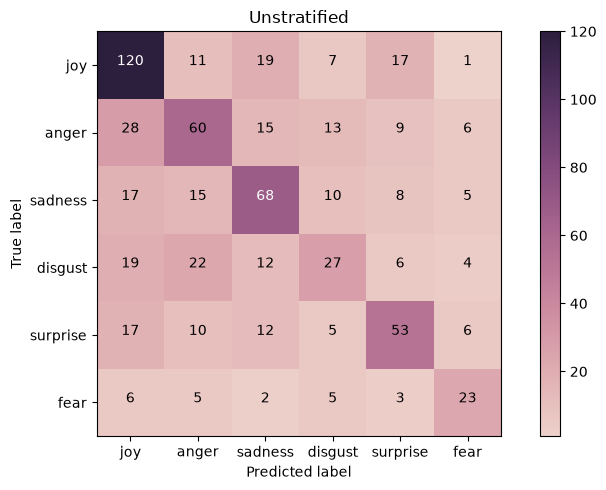

In [28]:
clf_un, pred_un = train_and_evaluate(X_tr_un, tr_df["label"],
                                     X_val_un, val_df["label"], "Unstratified")

=== Stratified ===
              precision    recall  f1-score   support

       anger       0.41      0.43      0.42       134
     disgust       0.38      0.28      0.32        90
        fear       0.50      0.30      0.38        56
         joy       0.55      0.71      0.62       174
     sadness       0.48      0.47      0.48       124
    surprise       0.49      0.44      0.47        88

    accuracy                           0.48       666
   macro avg       0.47      0.44      0.45       666
weighted avg       0.47      0.48      0.47       666



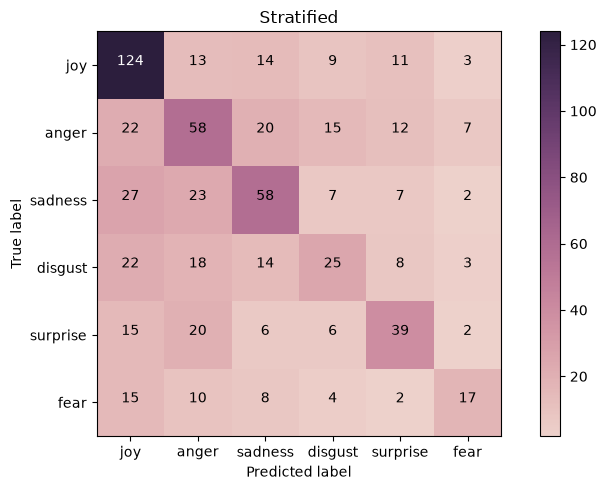

In [29]:
clf_st, pred_st = train_and_evaluate(X_tr_st, str_tr_df["label"],
                                     X_val_st, str_val_df["label"], "Stratified")

In [30]:
# Grid search over params
pipe = Pipeline([
    ("tfidf", make_tfidf()),
    ("svm", LinearSVC()),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__min_df": [1, 2, 3, 4],
    "tfidf__sublinear_tf": [False, True],
    "svm__C": [0.001, 0.05, 0.1, 0.3, 0.5, 1.0, 2, 3],
    "svm__class_weight": [None, "balanced"],
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipe, param_grid, cv=skf, scoring="f1_macro",
                      n_jobs=6, return_train_score=True)
search.fit(str_tr_df["tokens"], str_tr_df["label"]) # tune on the training split only

results = pd.DataFrame(search.cv_results_)
cols = ["params", "mean_test_score", "std_test_score", "mean_train_score"]
display(results.sort_values("rank_test_score")[cols].head(10))

,params,mean_test_score,std_test_score,mean_train_score
169,"{'svm__C': 0.3, 'svm__class_weight': 'balanced...",0.488084,0.012906,0.968897
168,"{'svm__C': 0.3, 'svm__class_weight': 'balanced...",0.484893,0.011711,0.965279
216,"{'svm__C': 0.5, 'svm__class_weight': 'balanced...",0.483438,0.011774,0.981859
217,"{'svm__C': 0.5, 'svm__class_weight': 'balanced...",0.482380,0.015433,0.983953
193,"{'svm__C': 0.5, 'svm__class_weight': None, 'tf...",0.479576,0.015573,0.982117
151,"{'svm__C': 0.3, 'svm__class_weight': None, 'tf...",0.478381,0.013960,0.901188
175,"{'svm__C': 0.3, 'svm__class_weight': 'balanced...",0.477605,0.009283,0.915344
145,"{'svm__C': 0.3, 'svm__class_weight': None, 'tf...",0.476535,0.011792,0.964163
199,"{'svm__C': 0.5, 'svm__class_weight': None, 'tf...",0.476521,0.013027,0.937100
192,"{'svm__C': 0.5, 'svm__class_weight': None, 'tf...",0.476312,0.012514,0.980450


best params: {'svm__C': 0.3, 'svm__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}
CV macro F1: 0.488
              precision    recall  f1-score   support

       anger       0.44      0.47      0.46       134
     disgust       0.36      0.31      0.34        90
        fear       0.46      0.38      0.41        56
         joy       0.59      0.68      0.63       174
     sadness       0.53      0.51      0.52       124
    surprise       0.51      0.48      0.49        88

    accuracy                           0.50       666
   macro avg       0.48      0.47      0.48       666
weighted avg       0.50      0.50      0.50       666



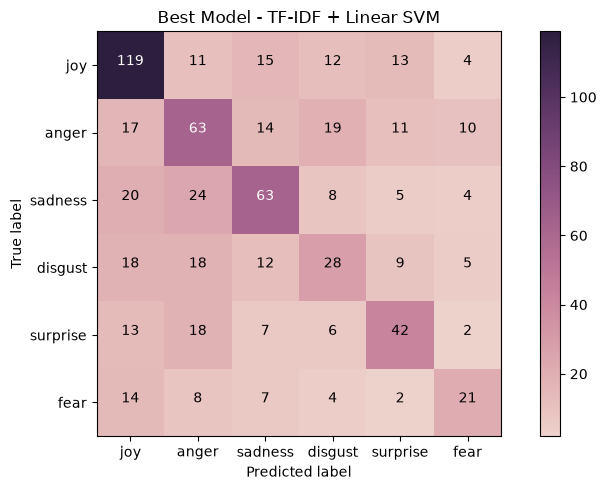

In [31]:
# Final check on the held-out split, which the grid search never saw
val_pred = search.predict(str_val_df["tokens"])
print("best params:", search.best_params_)
print(f"CV macro F1: {search.best_score_:.3f}")
print(classification_report(str_val_df["label"], val_pred))
plot_confusion_matrix(confusion_matrix(str_val_df["label"], val_pred, labels=LABELS), LABELS, title="Best Model - TF-IDF + Linear SVM")

In [32]:
final_model = clone(search.best_estimator_)
final_model.fit(train_df["tokens"], train_df["label"])
test_pred = final_model.predict(test_df["tokens"])

sample = pd.read_csv(f"{DATA_DIR}/sampleSubmission.csv")
submission = pd.DataFrame({"id": test_df["post_id"], "label": test_pred})
assert len(submission) == len(sample) and set(submission.id) == set(sample.post_id)
submission.to_csv("submission_tfidf_svm.csv", index=False)
print(submission["label"].value_counts(normalize=True).round(3))

label
joy         0.267
anger       0.215
sadness     0.173
surprise    0.139
disgust     0.128
fear        0.078
Name: proportion, dtype: float64


In [33]:
emb_weights = [{"tfidf": 1, "emb": w} for w in [0.1, 0.5, 1, 2]]
emb_param_grid = [
    {   # Linear SVM
        "features__transformer_weights": emb_weights,
        "clf": [LinearSVC(class_weight="balanced")],
        "clf__C": [0.01, 0.03, 0.05, 0.1, 0.3, 1.0, 1.5, 2.0, 3.0],
    },
    {   # Logistic regression
        "features__transformer_weights": emb_weights,
        "clf": [LogisticRegression(class_weight="balanced", max_iter=3000)],
        "clf__C": [0.01, 0.03, 0.05, 0.1, 0.3, 1.0, 1.5, 2.0, 3.0],
    },
]

# Reference row: the TF-IDF-only search from earlier
comparison = [{"model": "TF-IDF only", "cv_macro_f1": search.best_score_,
               "holdout_macro_f1": f1_score(str_val_df["label"], search.predict(str_val_df["tokens"]), average="macro")}]

emb_searches = {}
for short in EMBEDDERS:
    emb_cols = ["tokens", f"emb_{short}"]
    emb_pipe = Pipeline([
        ("features", make_emb_features(f"emb_{short}", sublinear_tf=True)),
        ("clf", LinearSVC(class_weight="balanced")),
    ])
    emb_search = GridSearchCV(emb_pipe, emb_param_grid, cv=skf, # same folds as TF-IDF only
                              scoring="f1_macro", n_jobs=6)
    emb_search.fit(feat_tr_df[emb_cols], feat_tr_df["label"])
    emb_searches[short] = emb_search

    r = pd.DataFrame(emb_search.cv_results_)
    r["clf_name"] = r["param_clf"].map(lambda m: type(m).__name__)
    best_per_clf = r.loc[r.groupby("clf_name")["mean_test_score"].idxmax(),
                         ["clf_name", "param_clf__C", "mean_test_score", "std_test_score"]]
    print(short); display(best_per_clf.round(3))

    holdout_pred = emb_search.predict(feat_val_df[emb_cols])
    best_clf = emb_search.best_estimator_.named_steps["clf"]
    comparison.append({"model": f"TF-IDF + {short}", "cv_macro_f1": emb_search.best_score_,
                       "holdout_macro_f1": f1_score(feat_val_df["label"], holdout_pred, average="macro"),
                       "clf": type(best_clf).__name__, "emb_weight": emb_search.best_params_["features__transformer_weights"]["emb"],
                       "best_params": emb_search.best_params_})

minilm


,clf_name,param_clf__C,mean_test_score,std_test_score
14,LinearSVC,0.1,0.538,0.019
58,LogisticRegression,1.0,0.531,0.017


mpnet


,clf_name,param_clf__C,mean_test_score,std_test_score
10,LinearSVC,0.05,0.544,0.012
61,LogisticRegression,1.50,0.542,0.015


,model,cv_macro_f1,holdout_macro_f1,clf,emb_weight,best_params
0,TF-IDF only,0.488,0.476,NaN,NaN,NaN
1,TF-IDF + minilm,0.538,0.507,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.1, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}"
2,TF-IDF + mpnet,0.544,0.515,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}"


              precision    recall  f1-score   support

       anger       0.51      0.61      0.55       134
     disgust       0.44      0.31      0.37        90
        fear       0.49      0.57      0.53        56
         joy       0.66      0.78      0.71       174
     sadness       0.55      0.43      0.48       124
    surprise       0.50      0.41      0.45        88

    accuracy                           0.55       666
   macro avg       0.52      0.52      0.52       666
weighted avg       0.54      0.55      0.54       666



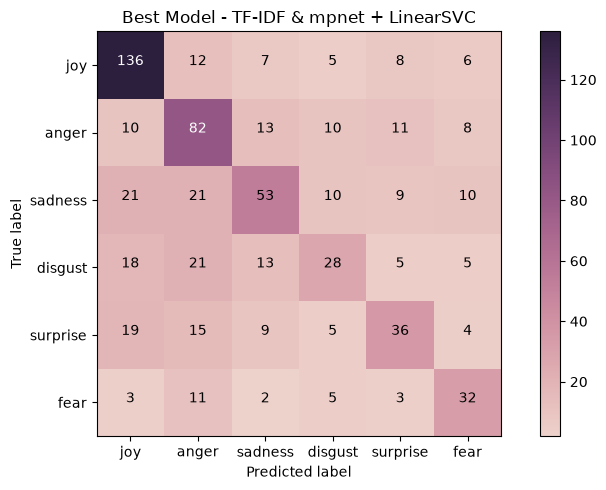

In [34]:
best_short = max(emb_searches, key=lambda short: emb_searches[short].best_score_)
best_cols = ["tokens", f"emb_{best_short}"]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(comparison).round(3))
emb_val_pred = emb_searches[best_short].predict(feat_val_df[best_cols])

print(classification_report(feat_val_df["label"], emb_val_pred))
best_clf_name = type(emb_searches[best_short].best_estimator_.named_steps["clf"]).__name__
plot_confusion_matrix(confusion_matrix(feat_val_df["label"], emb_val_pred, labels=LABELS),
                      LABELS, title=f"Best Model - TF-IDF & {best_short} + {best_clf_name}")

In [35]:
print("CV macro F1 per embedder:",
      {short: round(s.best_score_, 3) for short, s in emb_searches.items()})
print("selected:", best_short, "with", emb_searches[best_short].best_params_)

emb_final_model = clone(emb_searches[best_short].best_estimator_)
emb_final_model.fit(train_df[best_cols], train_df["label"]) # all training data
emb_test_pred = emb_final_model.predict(test_df[best_cols])

emb_submission = pd.DataFrame({"id": test_df["post_id"], "label": emb_test_pred})
assert len(emb_submission) == 1440 and set(emb_submission["label"]) <= set(LABELS)
assert len(emb_submission) == len(sample) and set(emb_submission.id) == set(sample.post_id)
emb_submission.to_csv(f"submission_tfidf_{best_short}_{best_clf_name}.csv", index=False)
print(emb_submission["label"].value_counts(normalize=True).round(3))

CV macro F1 per embedder: {'minilm': np.float64(0.538), 'mpnet': np.float64(0.544)}
selected: mpnet with {'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}
label
joy         0.277
anger       0.214
sadness     0.174
surprise    0.129
disgust     0.117
fear        0.089
Name: proportion, dtype: float64


,model,cv_macro_f1,holdout_macro_f1,clf,emb_weight,best_params,train_macro_f1
0,TF-IDF only,0.488,0.476,NaN,NaN,NaN,NaN
1,TF-IDF + minilm,0.538,0.507,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.1, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN
2,TF-IDF + mpnet,0.544,0.515,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN
3,jhartmann zero-shot,NaN,0.551,NaN,NaN,NaN,0.569
4,samlowe zero-shot,NaN,0.511,NaN,NaN,NaN,0.564


=== Best zero-shot: jhartmann (holdout) ===
              precision    recall  f1-score   support

       anger       0.53      0.47      0.50       134
     disgust       0.37      0.57      0.45        90
        fear       0.53      0.54      0.53        56
         joy       0.86      0.70      0.77       174
     sadness       0.61      0.44      0.51       124
    surprise       0.47      0.65      0.55        88

    accuracy                           0.57       666
   macro avg       0.56      0.56      0.55       666
weighted avg       0.60      0.57      0.57       666



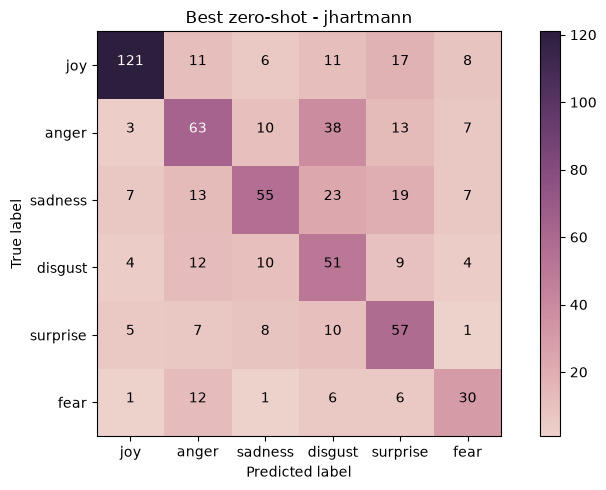

In [36]:
comparison = [row for row in comparison if "zero-shot" not in row["model"]]  # no duplicate rows on re-run

pt_results = {}
for short in EMOTION_MODELS:
    probs = {name: to_six(np.vstack(df[f"emo_{short}"]), EMO_LABELS[short], EMOTION_KIND[short])
             for name, df in [("holdout", feat_val_df), ("train", train_df)]}
    pt_val_pred = np.array(LABELS)[probs["holdout"].argmax(axis=1)]
    pt_train_pred = np.array(LABELS)[probs["train"].argmax(axis=1)]

    pt_results[short] = {"val_pred": pt_val_pred,
                         "train_f1": f1_score(train_df["label"], pt_train_pred, average="macro")}
    comparison.append({"model": f"{short} zero-shot",
                       "holdout_macro_f1": f1_score(feat_val_df["label"], pt_val_pred, average="macro"),
                       "train_macro_f1": pt_results[short]["train_f1"]})

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(comparison).round(3))

# Select on all of train (nothing was fitted, so no leakage), then report on the holdout
best_pt = max(pt_results, key=lambda short: pt_results[short]["train_f1"])
print(f"=== Best zero-shot: {best_pt} (holdout) ===")
print(classification_report(feat_val_df["label"], pt_results[best_pt]["val_pred"]))
plot_confusion_matrix(confusion_matrix(feat_val_df["label"], pt_results[best_pt]["val_pred"], labels=LABELS),
                      LABELS, title=f"Best zero-shot - {best_pt}")

In [43]:
EMO_SETS = {
    "jhartmann": ["emo_jhartmann"],
    "samlowe": ["emo_samlowe"],
    "jhartmann+samlowe": ["emo_jhartmann", "emo_samlowe"],
}
stack_emb_col = f"emb_{best_short}"  # best embedder from the previous search (mpnet)
emo_ws = [0.1, 0.2, 0.4, 0.7]
emb_ws = [0.5, 1, 1.5]

comparison = [row for row in comparison if not row["model"].startswith("stack")]  # no duplicates on re-run
stack_searches = {}
for name, emo_cols in EMO_SETS.items():
    stack_cols = ["tokens", stack_emb_col] + emo_cols
    weights = [{"tfidf": 1, "emb": e, **{c: w for c in emo_cols}} for e in emb_ws for w in emo_ws]
    stack_param_grid = [
        {"features__transformer_weights": weights,
         "clf": [LinearSVC(class_weight="balanced", max_iter=3000)], "clf__C": [0.005, 0.01, 0.02, 0.03, 0.05, 0.1]},
        {"features__transformer_weights": weights,
         "clf": [LogisticRegression(class_weight="balanced", max_iter=3000)], "clf__C": [0.3, 0.5, 1, 1.5, 2, 3]},
    ]
    stack_pipe = Pipeline([
        ("features", make_stack_features(stack_emb_col, emo_cols, sublinear_tf=True)),
        ("clf", LinearSVC(class_weight="balanced")),
    ])
    stack_search = GridSearchCV(stack_pipe, stack_param_grid, cv=skf,  # same folds as before
                                scoring="f1_macro", n_jobs=8)
    stack_search.fit(feat_tr_df[stack_cols], feat_tr_df["label"])
    stack_searches[name] = stack_search

    stack_holdout_pred = stack_search.predict(feat_val_df[stack_cols])
    bp = stack_search.best_params_
    comparison.append({"model": f"stack: TF-IDF + {best_short} + {name}",
                       "cv_macro_f1": stack_search.best_score_,
                       "holdout_macro_f1": f1_score(feat_val_df["label"], stack_holdout_pred, average="macro"),
                       "clf": type(bp["clf"]).__name__,
                       "emo_weight": bp["features__transformer_weights"][emo_cols[0]],
                       "emb_weight": bp["features__transformer_weights"]["emb"],
                       "best_params": bp})

,model,cv_macro_f1,holdout_macro_f1,clf,emb_weight,best_params,train_macro_f1,emo_weight
0,TF-IDF only,0.488,0.476,NaN,NaN,NaN,NaN,NaN
1,TF-IDF + minilm,0.538,0.507,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.1, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN,NaN
2,TF-IDF + mpnet,0.544,0.515,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN,NaN
3,jhartmann zero-shot,NaN,0.551,NaN,NaN,NaN,0.569,NaN
4,samlowe zero-shot,NaN,0.511,NaN,NaN,NaN,0.564,NaN
5,stack: TF-IDF + mpnet + jhartmann,0.614,0.583,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.01, 'features__transformer_weights': {'tfidf': 1, 'emb': 1, 'emo_jhartmann': 0.2}}",NaN,0.2
6,stack: TF-IDF + mpnet + samlowe,0.635,0.612,LinearSVC,1.5,"{'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.03, 'features__transformer_weights': {'tfidf': 1, 'emb': 1.5, 'emo_samlowe': 0.4}}",NaN,0.4
7,stack: TF-IDF + mpnet + jhartmann+samlowe,0.639,0.633,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.03, 'features__transformer_weights': {'tfidf': 1, 'emb': 1, 'emo_jhartmann': 0.4, 'emo_samlowe': 0.4}}",NaN,0.4


=== Best stack: jhartmann+samlowe + LinearSVC (holdout) ===
              precision    recall  f1-score   support

       anger       0.62      0.63      0.62       134
     disgust       0.55      0.46      0.50        90
        fear       0.66      0.68      0.67        56
         joy       0.72      0.84      0.78       174
     sadness       0.63      0.60      0.61       124
    surprise       0.66      0.58      0.62        88

    accuracy                           0.65       666
   macro avg       0.64      0.63      0.63       666
weighted avg       0.65      0.65      0.65       666



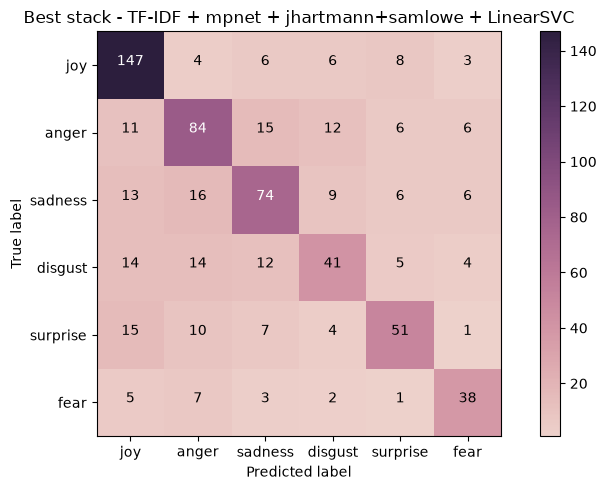

In [44]:
best_stack = max(stack_searches, key=lambda name: stack_searches[name].best_score_)
best_stack_cols = ["tokens", stack_emb_col] + EMO_SETS[best_stack]
best_stack_clf = type(stack_searches[best_stack].best_params_["clf"]).__name__

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(comparison).round(3))

stack_val_pred = stack_searches[best_stack].predict(feat_val_df[best_stack_cols])
print(f"=== Best stack: {best_stack} + {best_stack_clf} (holdout) ===")
print(classification_report(feat_val_df["label"], stack_val_pred))
plot_confusion_matrix(confusion_matrix(feat_val_df["label"], stack_val_pred, labels=LABELS),
                      LABELS, title=f"Best stack - TF-IDF + {best_short} + {best_stack} + {best_stack_clf}")

In [45]:
print("CV macro F1 per set:", {n: round(s.best_score_, 3) for n, s in stack_searches.items()})
print("selected:", best_stack, "with", stack_searches[best_stack].best_params_)

stack_final_model = clone(stack_searches[best_stack].best_estimator_)
stack_final_model.fit(train_df[best_stack_cols], train_df["label"])  # all training data
stack_test_pred = stack_final_model.predict(test_df[best_stack_cols])

stack_submission = pd.DataFrame({"id": test_df["post_id"], "label": stack_test_pred})
assert len(stack_submission) == len(sample) and set(stack_submission.id) == set(sample.post_id)
assert set(stack_submission["label"]) <= set(LABELS)
stack_submission.to_csv(f"submission_stack_{best_short}_{best_stack}_{best_stack_clf}.csv", index=False)
print(stack_submission["label"].value_counts(normalize=True).round(3))

CV macro F1 per set: {'jhartmann': np.float64(0.614), 'samlowe': np.float64(0.635), 'jhartmann+samlowe': np.float64(0.639)}
selected: jhartmann+samlowe with {'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.03, 'features__transformer_weights': {'tfidf': 1, 'emb': 1, 'emo_jhartmann': 0.4, 'emo_samlowe': 0.4}}
label
joy         0.269
anger       0.213
sadness     0.187
surprise    0.138
disgust     0.109
fear        0.085
Name: proportion, dtype: float64
